# KV-Cache Scaling — final deliverables and live presentation

**Run all on a CPU runtime.** This notebook regenerates and presents real saved GPU evidence. It never loads model weights, allocates CUDA memory or consumes an OOM attempt. All six requested deliverables appear as separate sections.

**Research status:** 80 successful workers are saved. Colab GPU quota blocked two validation repeats and the final boundary attempt. Successful context is a lower bound; no OOM threshold is claimed.

The five-phase implementation and decision guide is `docs/DECISIONS_AND_PHASE_GUIDE.md`. Historical raw evidence and the original prediction remain unchanged.

In [1]:
# Reproducible setup: no GPU package imports or Google Drive mount.
import os, sys, json, subprocess, tempfile, hashlib, shutil
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
from IPython.display import display, Markdown, HTML
SOURCE_COMMIT='e33b3992341e7b7d3a0a8e56326f0a1d1b08e928'
REPOSITORY_URL='https://github.com/DevanshSharma351/KV-Cache-Scaling.git'
ROOT=Path(os.environ.get('KV_CACHE_ROOT',Path.cwd())).resolve()
if not (ROOT/'src/kv_cache_scaling/presentation.py').is_file():
    ROOT=Path('/content')/('kv-cache-presentation-'+SOURCE_COMMIT[:8])
    if not ROOT.exists():
        subprocess.run(['git','clone','--quiet',REPOSITORY_URL,str(ROOT)],check=True)
        subprocess.run(['git','-C',str(ROOT),'checkout','--quiet','--detach',SOURCE_COMMIT],check=True)
actual_commit=subprocess.check_output(['git','-C',str(ROOT),'rev-parse','HEAD'],text=True).strip()
assert actual_commit==SOURCE_COMMIT,'Use the pinned source checkout; do not silently present changed code.'
assert not subprocess.check_output(['git','-C',str(ROOT),'status','--porcelain','--untracked-files=normal'],text=True).strip(),'Use a clean source checkout; preserve edits before running the demo.'
expected={'matplotlib':'3.10.1','reportlab':'4.4.4','pypdf':'5.9.0'}
def installed(name):
    try:return version(name)
    except PackageNotFoundError:return None
if any(installed(k)!=v for k,v in expected.items()):
    subprocess.run([sys.executable,'-m','pip','install','--quiet','-e',str(ROOT),'-r',str(ROOT/'requirements-analysis.txt')],check=True)
sys.path.insert(0,str(ROOT/'src'))
print('Presentation source:',actual_commit)
print('Runtime:',sys.version.split()[0],'; CPU replay only; Drive disconnected')


Presentation source: e33b3992341e7b7d3a0a8e56326f0a1d1b08e928
Runtime: 3.12.14 ; CPU replay only; Drive disconnected


In [2]:
# Regenerate every graph/table/report from the immutable GPU capsule.
RESULTS=Path(os.environ['KV_CACHE_RESULTS']).resolve() if os.environ.get('KV_CACHE_RESULTS') else Path(tempfile.mkdtemp(prefix='kv-cache-presentation-'))/'results'
command=[sys.executable,str(ROOT/'scripts/reproduce_results.py'),'--capsule',str(ROOT/'artifacts/experiments/2026-10-19-t4-final/gpu-checkpoint-080.zip'),'--output',str(RESULTS)]
print('Recorded command:',json.dumps(command))
completed=subprocess.run(command,cwd=ROOT,text=True,capture_output=True,timeout=1200)
print(completed.stdout)
if completed.returncode:print(completed.stderr);raise RuntimeError('Reproduction failed; inspect saved logs before presenting.')
from kv_cache_scaling.presentation import Presentation,checkpoint_demo,table
presentation=Presentation(ROOT,RESULTS)
print('All generated manifests, raw capsule hash and original prediction bytes verified.')
presentation.show('overview')


Recorded command: ["/tmp/kvcache-report-env/bin/python", "/Users/devanshsharma/Documents/KV-Cache/KV-Cache-Scaling/scripts/reproduce_results.py", "--capsule", "/Users/devanshsharma/Documents/KV-Cache/KV-Cache-Scaling/artifacts/experiments/2026-10-19-t4-final/gpu-checkpoint-080.zip", "--output", "/private/tmp/kv-project-presentation-release/reproduction"]


Reproduced saved evidence: /private/tmp/kv-project-presentation-release/reproduction

All generated manifests, raw capsule hash and original prediction bytes verified.


# KV-Cache Scaling
## Predicting the context limit before you hit it
We built an analytical predictor, a checkpointing GPU harness, and a reproducible evidence pipeline. This presentation exposes all six required deliverables separately from the PDF.

Evidence,Actual result
Saved GPU workers,80
Primary model,"Qwen2.5-1.5B, FP16, batch 1"
Largest successful prefill,"114,688 tokens with both allocators"
KV storage slope,"28,672 bytes/token; exact agreement with theory"
Research status,Incomplete boundary evidence: Colab GPU usage limit
Demo mode,CPU replay of real saved measurements; no model load or OOM attempt


Measured environment,Recorded value
GPU UUID,GPU-89f781af-1ec0-992b-3dc3-46ef2d0941de
Driver,580.82.07
PyTorch / CUDA runtime,2.6.0+cu124 / 12.4
Transformers,4.51.3
Context-adjusted usable bytes,15527116800
Model revision,8faed761d45a263340a0528343f099c05c9a4323


### Five phases followed
1. Derive and preregister the prediction.
2. Implement and verify the isolated probe.
3. Add checkpointing, recovery and safe scheduling.
4. Measure curves and account for discrepancies.
5. Generalize, reproduce and present the results.

## 1. Derivation

In [3]:
presentation.show('derivation')


## Deliverable 1 — Derivation and defined symbols
Sequence length **L** means one cold forward pass over exactly L tokens, starting with an empty DynamicCache. It is not generation to L. We use `logits_to_keep=1`, FP16 and forced efficient SDPA.

```text
M(L,B) = W + KV(L,B) + A(L,B) + H0
KV(L,B) = 2 × B × L × N × K × D × s
W = s × unique_parameter_count
```

Symbol,Meaning,Value / units
L,Input prefill sequence length,tokens
B,Batch size,1 measured; variable in theory
N,Transformer layers,28
Q / K,Query / KV heads,12 / 2
D,Head dimension,128
s,Bytes per FP16 element,2
W,Unique tied FP16 weights,"3,087,428,608 bytes"
A,Length-dependent activation/workspace envelope,assumed before measurement; diagnostics assess it
H0,Fixed budget allowance,"536,870,912 bytes in central scenario"


**Result:** `KV(L,B) = 28,672 × B × L bytes`. Using Q instead of K gives a **6× overestimate**. Counting tied input/output embeddings twice adds **466,747,392 bytes**. Architecture values come from the pinned model config.

Unique parameter formula (all biases/norms included):
```text
P = V×H + N×[H×q + 2H×k + q×H + q + 2k + 3H×I + 2H] + H
q = Q×D; k = K×D; H = 1536; I = 8960; V = 151936
P = 1,543,714,304; W = 2P
```
The full derivation and lifetime assumptions are in `docs/DERIVATION.md`.

## 2. Preregistered prediction

In [4]:
presentation.show('prediction')


## Deliverable 2 — Original preregistered prediction
**Committed before model measurements.** The original bytes and timestamp are preserved; later measurements do not replace the commitment.

- Commit: `7baff5121ed643f27ba06959065855a8913f8e8c`
- Original Git commit timestamp: **2026-10-18T19:54:52+05:30**
- Same instant in UTC: **2026-10-18T14:24:52+00:00**
- Later remote receipt observation: **2026-10-18T14:25:17.088511+00:00**
- Usable VRAM: **15,527,116,800 bytes**, after context, before weights.
- Central prediction: **111,232 tokens**; assumption range **76,024–131,072**.
- Model-card quality domain: 32,768; higher lengths are synthetic memory stress.

[Inspect the original commit](https://github.com/DevanshSharma351/KV-Cache-Scaling/commit/7baff5121ed643f27ba06959065855a8913f8e8c).

L tokens,KV bytes,Predicted tensor peak bytes,Predicted budget bytes incl. H0
512,14680064,3142216704,3679087616
1024,29360128,3197004800,3733875712
2048,58720256,3306580992,3843451904
4096,117440512,3525733376,4062604288
8192,234881024,3964038144,4500909056


Parametric prediction: `L_max(U,B) = max(0, floor((U − W − H0) / (B × (28,672 + a))))`, capped by the config when reported. Central `a = 78,336 bytes/token`. U is context-adjusted usable VRAM, not the GPU label. The range is sensitivity to assumptions, not a confidence interval.

In [5]:
# Change these inputs during a live demo; only analytical arithmetic runs.
USABLE_VRAM_GIB = 14.46075439453125 #@param {type:"number"}
BATCH_SIZE = 1 #@param {type:"integer"}
presentation.show_explorer(USABLE_VRAM_GIB,BATCH_SIZE)


### Live analytical VRAM / batch explorer
Change the two inputs and rerun this cell. These are theoretical scenario predictions; no GPU measurement runs.

Scenario,Uncapped predicted tokens,Config-capped predicted tokens
optimistic,146740,131072
central,111232,111232
conservative,76024,76024


## 3. Checkpointing harness

In [6]:
presentation.show('checkpointing')


## Deliverable 3 — Checkpointing sweep harness
Each probe uses a new process. Allocator variables are set before CUDA initialization; load and forward peaks are measured separately with a peak reset. Worker output is saved, fsynced, mirrored and verified before another dispatch.

The immutable ZIP contains the real raw records, journals, command logs and external checksum acknowledgements. This is how the 80 measurements survived Colab runtime loss.

Scope,Saved workers,Journal state
Primary paired sweep,48,Finished
Diagnostics,28,Finished
Held-out validation,4,"Interrupted: default 3, expandable 1"
Final deliberate boundary attempt,0,Not dispatched; allowance unused


**Saved checkpoint SHA-256:** `cd0dedd8185a876e1a600b2c3ec8a1b95ac3701f8e22be57d2bab82f51c9c389`

Live CPU recovery demonstration below uses a temporary directory. Its events are explicitly demo events, never GPU measurements. No OOM token is consumed.

In [7]:
demonstration=checkpoint_demo()
display(HTML(table(['Temporary CPU recovery check','Result'],list(demonstration.items()))))


Temporary CPU recovery check,Result
mode,CPU temporary-filesystem demonstration; no model or OOM ledger
restored_missing_local_artifact,True
mirrored_journals_match,True
recovered_events,1


## 4. Analytical overlays and measured curves

## Deliverable 4 — Measured curves with analytical overlays
Points are actual observations; bands are advance assumptions. Repeats use fresh workers. The total-peak slope includes transient memory and must not be called the KV slope.

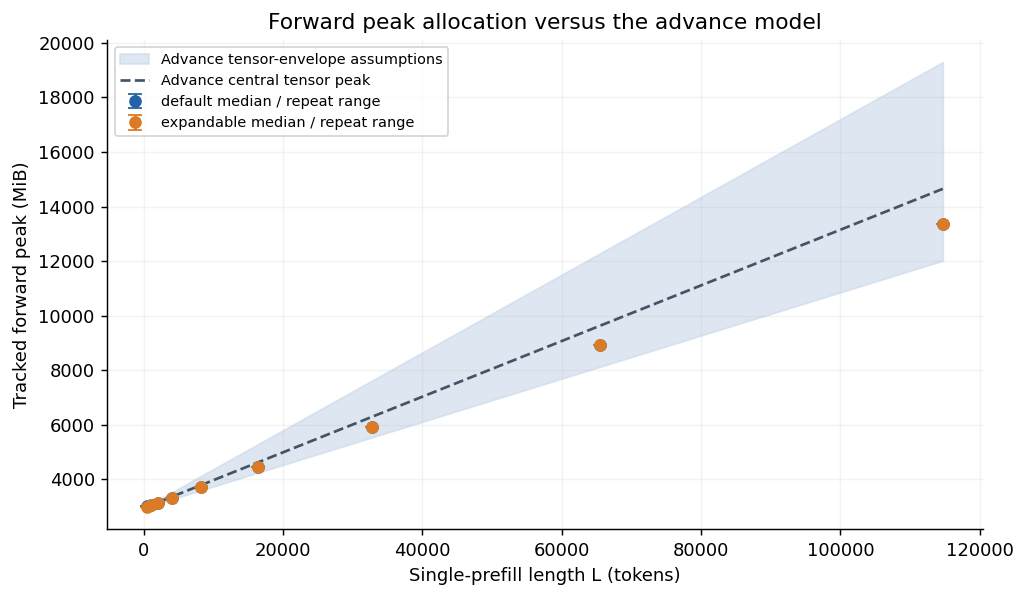

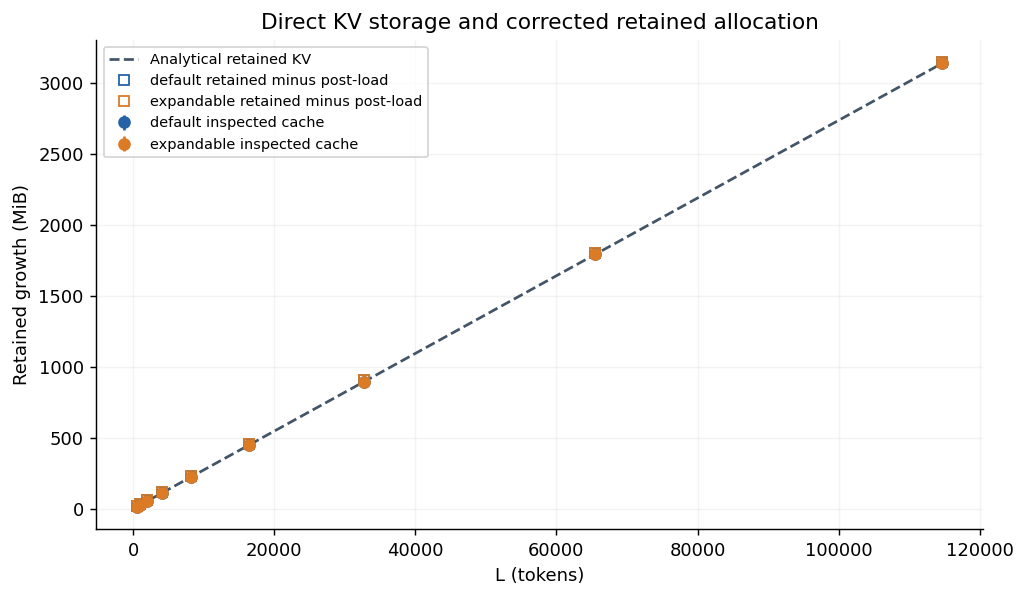

Allocator,Observed held-out L,Repeats,Peak allocated bytes,Frozen-fit prediction error %
default,114688,3,14020668928,-0.010449
expandable,114688,1,14019751424,0.0


The later fit was frozen before held-out execution. Its small error validates that later fit at this point; it does not turn the original commitment into an exact OOM prediction.

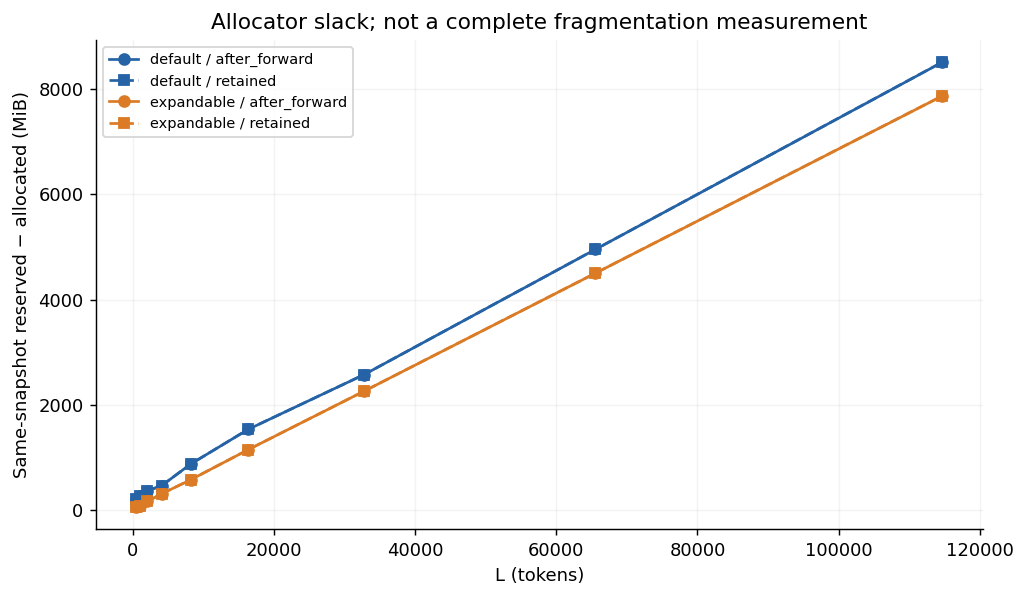

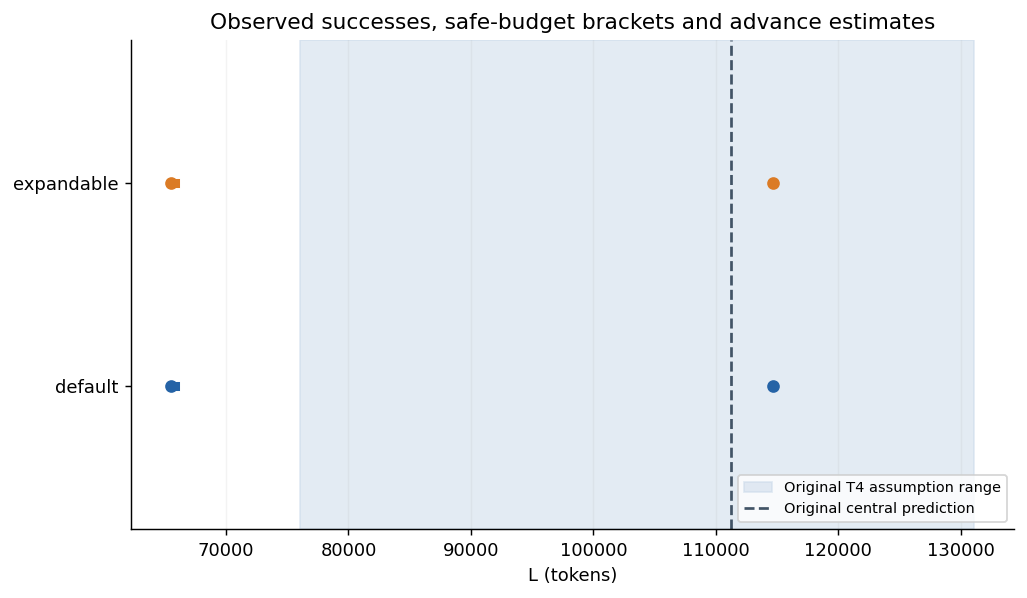

Reserved minus allocated at the same snapshot is allocator slack, not a pure fragmentation measurement. **114,688 is a successful lower bound; no failed upper bound was observed.** The safe-policy delta cannot establish the hardware-context benefit of expandable segments.

In [8]:
presentation.show('curves')


## 5. Discrepancy table

## Deliverable 5 — Discrepancy accounting, down to bytes
The table compares matching tracked tensor peaks at a fixed L. Fixed headroom H0 belongs to the budget model and is not silently compared with allocated tensor memory. Positive rows increase measured memory; negative rows reduce it.

Shown point: **default, L=114688, repeat 1**. Full repeat-level tables are downloadable below.

Component,Signed bytes,Signed MiB,Evidence / interpretation
unique_weight_difference,0,0.0,Deduplicated parameter storage vs config-derived weights
loaded_model_buffer_storage,256,0.000244,Unique loaded model storage excluding parameters
postload_allocator_internal_padding,917760,0.875244,Same-snapshot allocated minus requested bytes
unaccounted_postload_storage,0,0.0,Unclassified post-load allocation; not assumed to be framework overhead
controlled_cublas_workspace,8519680,8.125,"Source-supported fixed-size inference from same-allocator L=512 controls; not a direct intervention at this length; pinned PyTorch 2.6 fixed non-Hopper workspace; controls: 258f7320-7005-421e-a768-900f82727dcc,84065451-393c-4ffa-9aea-3e0385da962d,ab101abe-710e-4861-88c9-f7fa22042a87"
unaccounted_postforward_persistent_growth,0,0.0,Measured released-minus-postload allocation; physical cause unconfirmed
cache_lifetime_difference,0,0.0,Controlled cache release delta minus analytical retained KV
output_and_input_lifetime,2139136,2.040039,Controlled output/input release delta
transient_envelope_difference,-1350870016,-1288.290039,"Exact peak excess above synchronized endpoint minus assumed envelope; descriptive, not pure-activation attribution"


Check,Result
"Signed measured − predicted tensor peak, bytes",-1339293184
"Arithmetic closure error, bytes",0
Explicit unaccounted bytes,0
Coverage criterion,True


Separate planning budget,Bytes / interpretation
Original tensor-peak prediction,15359962112
Original fixed allowance H0,536870912
Original total budget prediction,15896833024
Caution,Advance planning allowance; do not subtract unrelated reservation/driver maxima


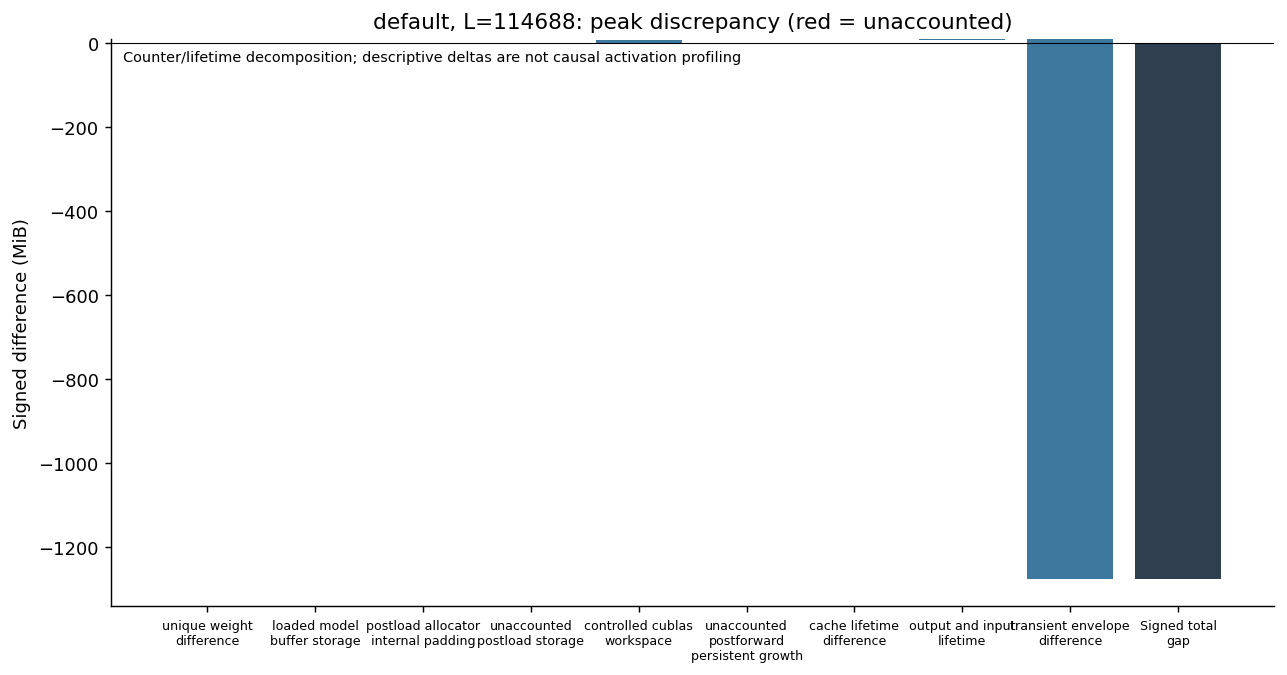

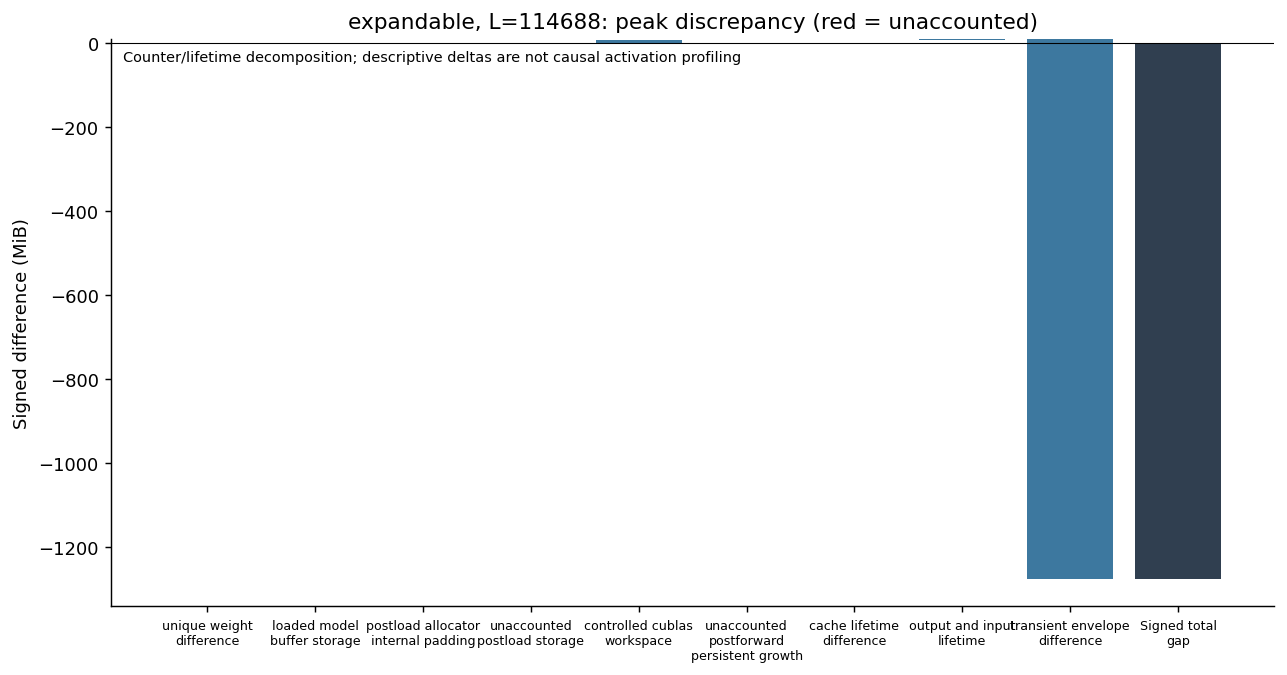

Lifetime/counter attribution is not a pure causal activation-versus-fragmentation decomposition. Matched zero-workspace controls support 8,519,680 bytes at L=512; other lengths use labelled fixed-size source inference. The true OOM-threshold gap remains unmeasured. StaticCache controls also include the pinned HF version’s L×L mask behavior.

In [9]:
presentation.show('discrepancy')


## 6. Cross-model / cross-GPU verification

In [10]:
presentation.show('transfer')


## Deliverable 6 — Cross-model / cross-GPU predictions and verification
The targets were not run: Qwen2.5-3B and Qwen2.5-7B on A100-40GB and RTX 4090-24GB. The measured model remains the required 1.5B model. Usable VRAM, activations, config caps and uncertainty are explicit assumptions.

# Config-derived transfer predictions

No target checkpoint was loaded and no target GPU was measured.

| Model | GPU | Assumed usable GiB (low/central/high) | Raw central L | Config-capped L | Capped assumption range |
| --- | --- | --- | ---: | ---: | --- |
| Qwen/Qwen2.5-3B | A100-40GB | 37/38/39 | 251278 | 32768 | 32768–32768 |
| Qwen/Qwen2.5-3B | RTX-4090-24GB | 22/23/23.5 | 132571 | 32768 | 32768–32768 |
| Qwen/Qwen2.5-7B | A100-40GB | 37/38/39 | 109629 | 109629 | 72387–131072 |
| Qwen/Qwen2.5-7B | RTX-4090-24GB | 22/23/23.5 | 39097 | 39097 | 22613–55262 |

Activation/VRAM ranges are assumptions, not statistical confidence intervals. Config censoring is not an observed OOM.

## Published KV-only comparison

Source: [Inside vLLM’s New KV Offloading Connector: Smarter Memory Transfer for Maximizing Inference Throughput](https://vllm-project.github.io/2026/01/08/kv-offloading-connector.html).

The publication uses MB without defining decimal versus binary units. Both errors are reported; the 2-byte cache dtype is an explicit compatibility assumption.

| Base / matching Instruct KV architecture | Predicted 16-token block bytes | Published MB | Error if MiB | Error if decimal MB |
| --- | ---: | ---: | ---: | ---: |
| Qwen/Qwen2.5-3B | 589824 | 0.56 | 0.4464% | 5.3257% |
| Qwen/Qwen2.5-7B | 917504 | 0.87 | 0.5747% | 5.4602% |

This checks KV-byte scaling only. It does not verify transferred HF single-prefill peak context limits.


The published serving-engine comparison verifies the compatible KV-block formula, with both MB interpretations reported. It does not independently verify HF peak context limits on the unrun GPUs.

## Conclusions and separate downloads
A CPU replay demonstrates reproducibility of saved measurements. It does not claim new GPU observations or finish the quota-blocked experiment.

## What we can defend in a live demo
- Unique weights and GQA-aware KV storage match the config equation.
- Both allocators successfully processed 114,688 tokens.
- All required short-length curves and diagnostic grids are saved.
- Original prediction, later validation and transfer estimates remain separate.
- CPU replay regenerates the plots, tables and report without a GPU.

## Remaining research evidence
- Paired prospective held-out validation at L=114688.
- Actual OOM boundary unobserved; conservative safe-budget censoring is not an OOM threshold.

Colab refused further GPU access because of its usage limit. Two expandable held-out repeats and the single registered boundary attempt remain. No OOM threshold, completed validation journal or independent human review is invented.

### Presentation and reproduction
Use **Runtime → Run all** in the clean presentation notebook on a CPU runtime. This replays saved measurements; it does not rerun the historical GPU sweep. For actual new GPU measurements, reconcile identity/runtime/usable memory and freeze a new prospective execution package first. Drive remains disconnected.

### Separate deliverable files
The links embed their files for standalone HTML use. In Colab, the optional download cell below is the recommended way to retrieve a file or one complete ZIP.


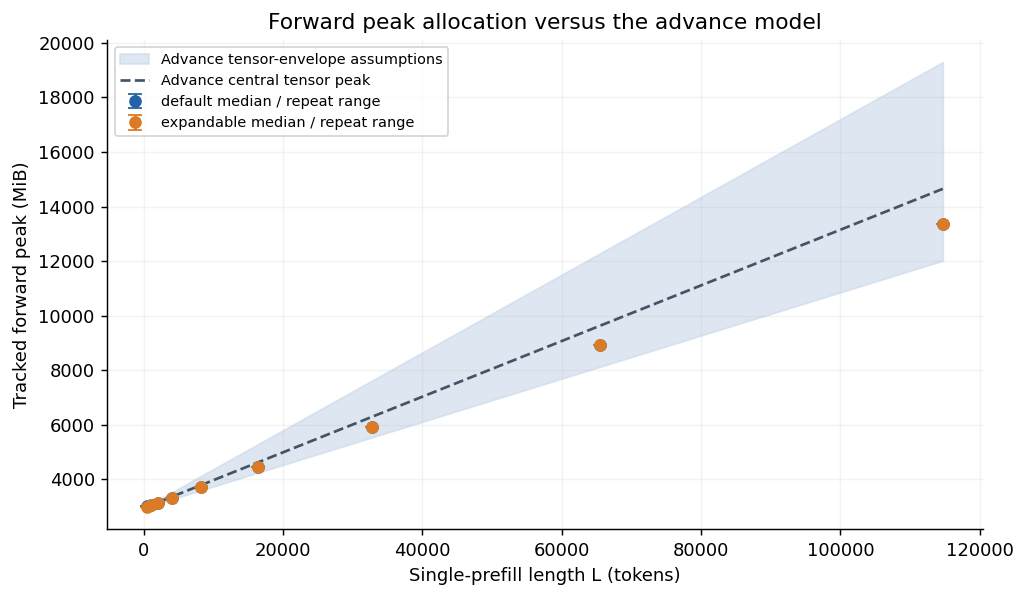
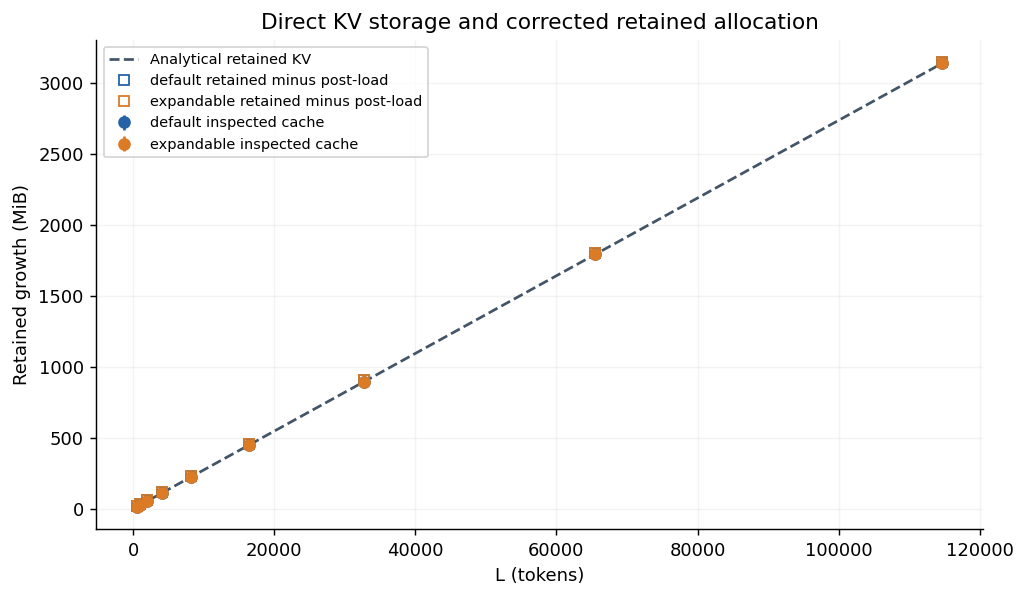
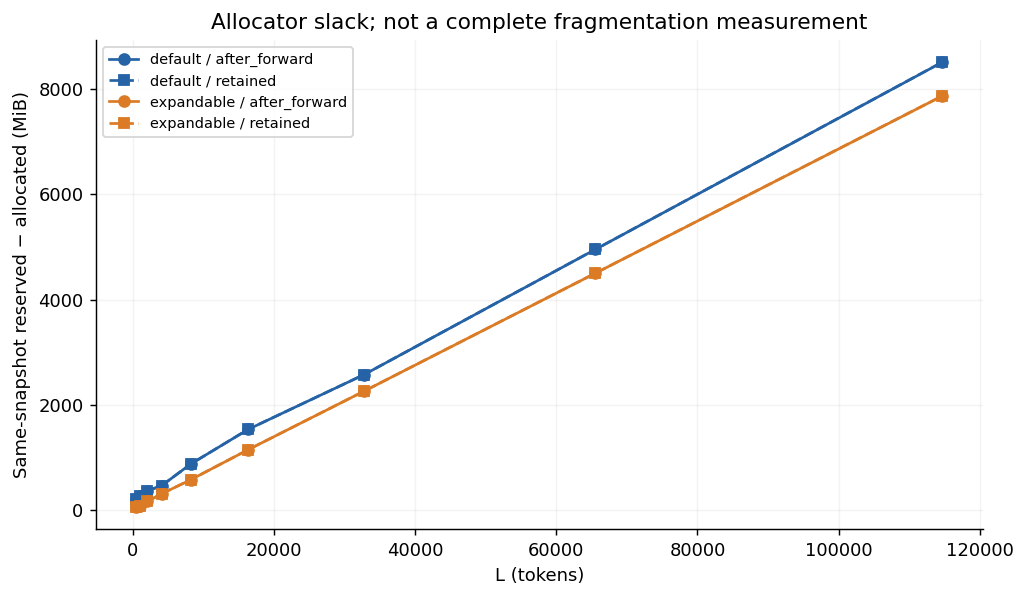
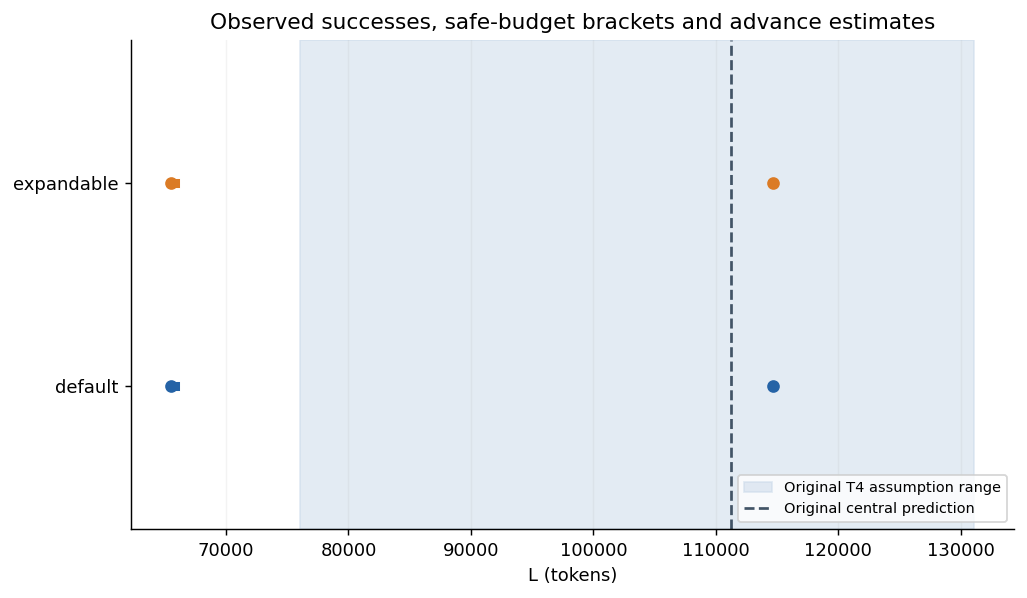
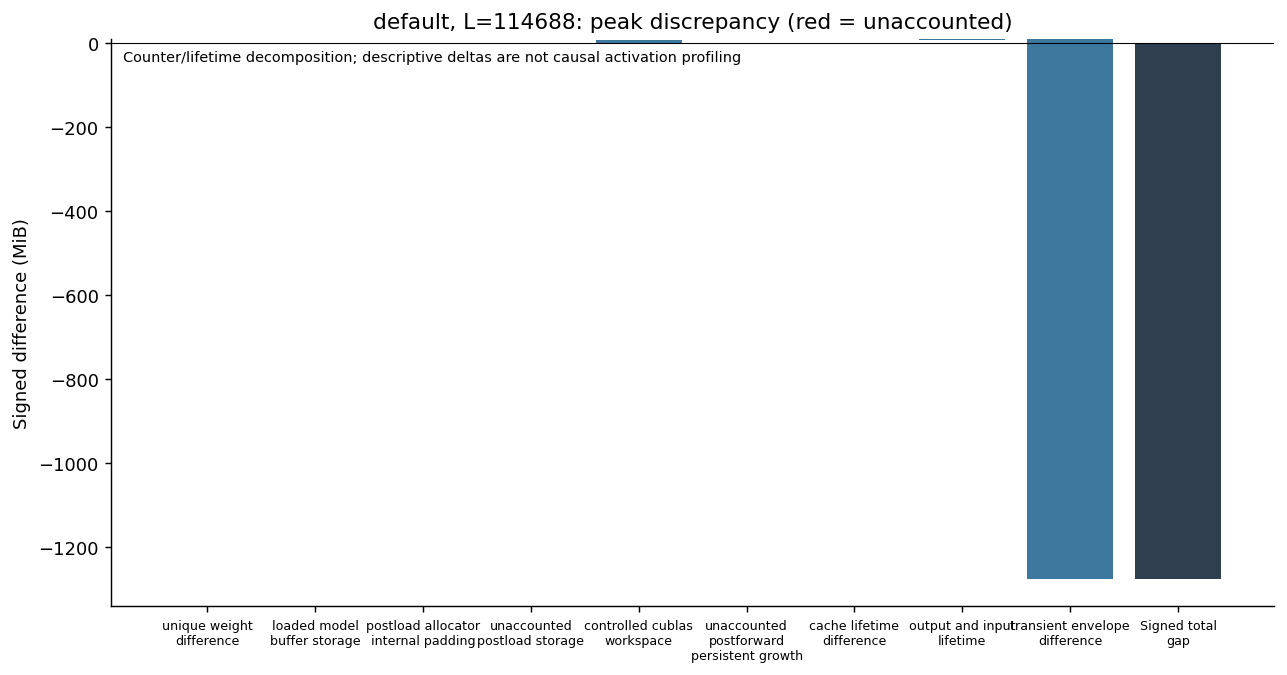
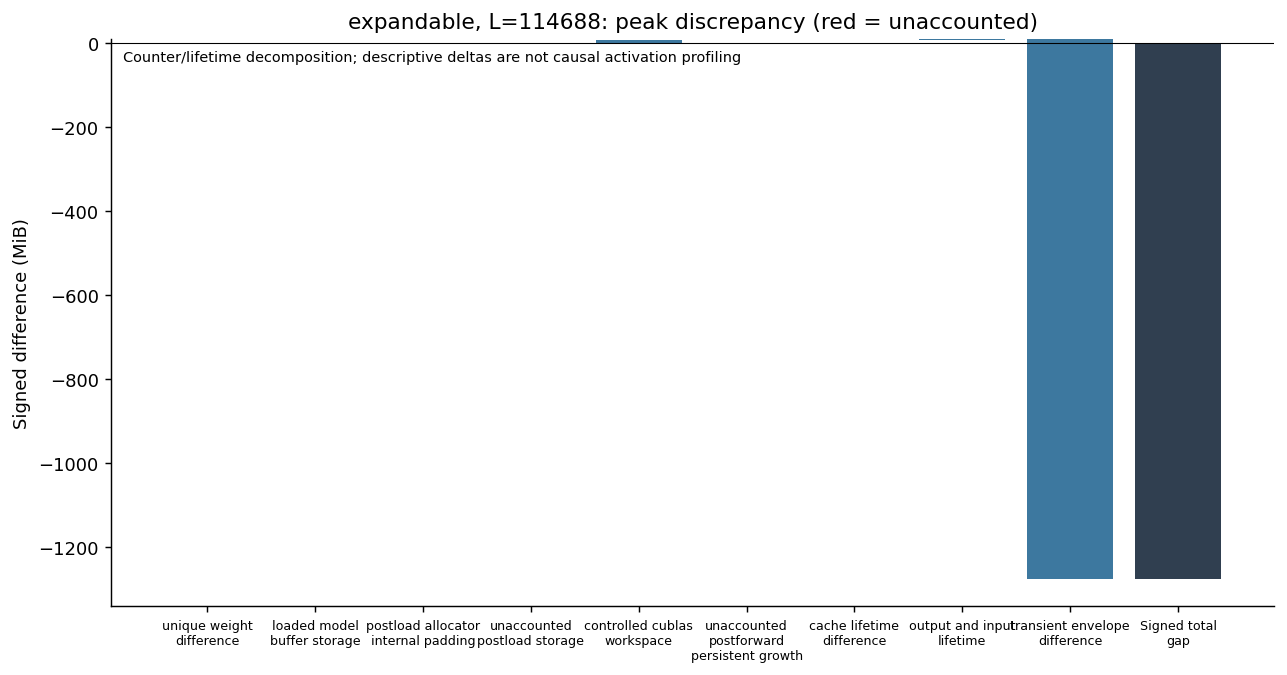

In [11]:
presentation.show('conclusions')
presentation.show_downloads()


In [12]:
# Optional download: default does not download anything.
DOWNLOAD_ARTIFACT = "none" #@param ["none", "report", "discrepancy_csv", "all_deliverables_zip"]
if DOWNLOAD_ARTIFACT=='none':
    print('Files remain available in RESULTS. Select an artifact above only when you want to download it.')
else:
    if DOWNLOAD_ARTIFACT=='report':selected=RESULTS/'report/report.pdf'
    elif DOWNLOAD_ARTIFACT=='discrepancy_csv':selected=RESULTS/'analysis/discrepancy.csv'
    elif DOWNLOAD_ARTIFACT=='all_deliverables_zip':
        export_root=RESULTS.parent/'all-deliverables'
        shutil.copytree(RESULTS,export_root,dirs_exist_ok=True)
        for relative in ['docs/DERIVATION.md','docs/DECISIONS_AND_PHASE_GUIDE.md','PHASES.md','prereg/formal-2026-10-18-t4/prediction.json','prereg/formal-2026-10-18-t4/prediction.md','prereg/formal-2026-10-18-t4/receipt.json','requirements-analysis.txt']:
            target=export_root/relative;target.parent.mkdir(parents=True,exist_ok=True);shutil.copyfile(ROOT/relative,target)
        shutil.copytree(ROOT/'src',export_root/'src',dirs_exist_ok=True)
        shutil.copytree(ROOT/'configs',export_root/'configs',dirs_exist_ok=True)
        shutil.copyfile(ROOT/'artifacts/experiments/2026-10-19-t4-final/gpu-checkpoint-080.zip',export_root/'gpu-checkpoint-080.zip')
        (export_root/'ORIGINAL_COMMIT.json').write_text(json.dumps({'commit':presentation.receipt['prediction_commit_sha'],'original_git_timestamp':presentation.commit_timestamp,'prediction_sha256':presentation.receipt['prediction_sha256']},indent=2))
        selected=Path(shutil.make_archive(str(RESULTS.parent/'kv-cache-deliverables'),'zip',export_root))
    else:raise ValueError('Unknown download choice')
    try:
        from google.colab import files
    except ImportError:print('Local artifact:',selected)
    else:files.download(str(selected))


Files remain available in RESULTS. Select an artifact above only when you want to download it.
